In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


In [9]:
# 1. Simulate Employee Dataset
np.random.seed(42)
n_samples = 1000

data = {
    'Employee_ID': range(1001, 1001 + n_samples),
    'Tenure_Years': np.random.randint(1, 10, size=n_samples),
    'Projects_Completed': np.random.randint(2, 15, size=n_samples),
    'Avg_Monthly_Hours': np.random.randint(130, 270, size=n_samples),
    'Training_Hours': np.random.randint(5, 40, size=n_samples),
    'Satisfaction_Score': np.random.uniform(1.0, 5.0, size=n_samples).round(1),
    'Last_Evaluation': np.random.uniform(0.5, 1.0, size=n_samples).round(2)
}

df = pd.DataFrame(data)

In [10]:
# Define Target Variable: High_Performer (1 if Evaluation >= 0.80 and Projects >= 8, else 0)
df['High_Performer'] = np.where(
    (df['Last_Evaluation'] >= 0.80) & (df['Projects_Completed'] >= 8), 1, 0
)

print("--- Dataset Sample ---")
print(df.head(), "\n")

--- Dataset Sample ---
   Employee_ID  Tenure_Years  Projects_Completed  Avg_Monthly_Hours  \
0         1001             7                   9                189   
1         1002             4                   8                222   
2         1003             8                  12                178   
3         1004             5                  14                164   
4         1005             7                   9                231   

   Training_Hours  Satisfaction_Score  Last_Evaluation  High_Performer  
0              19                 2.8             0.74               0  
1              34                 2.8             0.51               0  
2              39                 4.8             0.91               1  
3              27                 2.7             0.91               1  
4              10                 3.2             0.89               1   



In [11]:
# 2. Exploratory Data Analysis (EDA) Summary
print("--- Summary Statistics ---")
print(df.describe(), "\n")

# Check class distribution
print("--- Target Distribution ---")
print(df['High_Performer'].value_counts(normalize=True) * 100)

# 3. Feature Selection & Data Splitting
X = df[['Tenure_Years', 'Projects_Completed', 'Avg_Monthly_Hours', 'Training_Hours', 'Satisfaction_Score', 'Last_Evaluation']]
y = df['High_Performer']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


--- Summary Statistics ---
       Employee_ID  Tenure_Years  Projects_Completed  Avg_Monthly_Hours  \
count  1000.000000   1000.000000         1000.000000         1000.00000   
mean   1500.500000      4.898000            8.057000          199.39200   
std     288.819436      2.603916            3.805816           40.92069   
min    1001.000000      1.000000            2.000000          130.00000   
25%    1250.750000      3.000000            5.000000          164.00000   
50%    1500.500000      5.000000            8.000000          199.00000   
75%    1750.250000      7.000000           11.000000          236.00000   
max    2000.000000      9.000000           14.000000          269.00000   

       Training_Hours  Satisfaction_Score  Last_Evaluation  High_Performer  
count     1000.000000         1000.000000      1000.000000     1000.000000  
mean        22.009000            2.987400         0.747360        0.222000  
std         10.043894            1.159917         0.143206        

In [12]:
# 4. Train Machine Learning Model (Random Forest)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [13]:
# 5. Model Evaluation
y_pred = model.predict(X_test)

print("\n--- Model Evaluation ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


--- Model Evaluation ---
Accuracy Score: 1.0000

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       148
           1       1.00      1.00      1.00        52

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200




--- Feature Importances ---
Last_Evaluation       0.541083
Projects_Completed    0.381329
Training_Hours        0.022301
Avg_Monthly_Hours     0.022067
Satisfaction_Score    0.021911
Tenure_Years          0.011309
dtype: float64


C:\Users\sm768\AppData\Local\Temp\ipykernel_21984\2456875261.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='viridis')


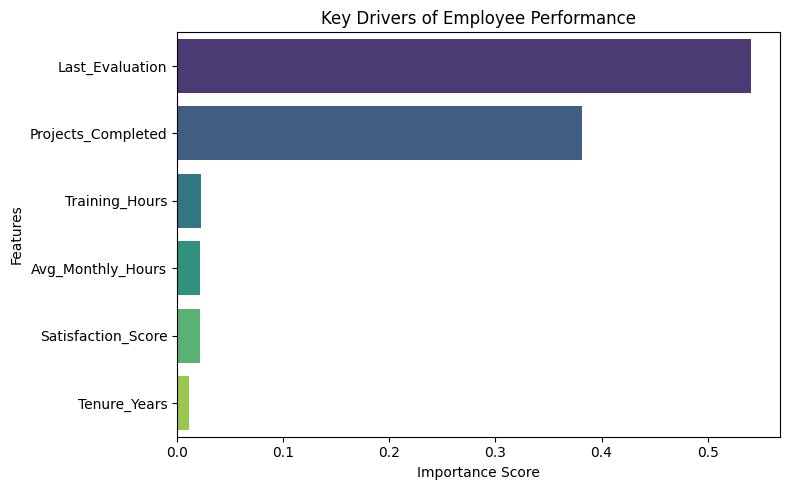

In [14]:
# 6. Feature Importance Analysis
feature_importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\n--- Feature Importances ---")
print(feature_importances)

# Optional: Plot Feature Importances
plt.figure(figsize=(8, 5))
sns.barplot(x=feature_importances.values, y=feature_importances.index, palette='viridis')
plt.title('Key Drivers of Employee Performance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()